# Tutorial 5 — Using a trained model

*Part 3 — Using models · tutorial 5 of 9 · previous: [04 Foundation models and fine-tuning](04_foundation_models_and_finetuning.ipynb) · next: [06 Surface-hopping dynamics with SHARC](06_surface_hopping_with_sharc.ipynb)*

With the model from Tutorial 3 we now

1. predict all properties for a geometry with the ASE calculator;
2. compare potential energy curves and couplings with the reference (LVC) along two
   distortions of SO2;
3. check the built-in symmetries on the trained model;
4. produce the quantities SHARC needs, in atomic units (`SharcCalculator`);
5. run adiabatic molecular dynamics on one excited state with ASE;
6. evaluate a whole file with `mace_eval_configs`.

**Requirements:** `work/so2.model` (Tutorial 3) and SHARC for the reference curves.
Runtime: about 2 minutes.

In [1]:
import subprocess
import sys
import warnings
from pathlib import Path

warnings.filterwarnings("ignore")

import ase
import ase.io
import matplotlib.pyplot as plt
import numpy as np

import mace  # noqa: F401
from mace.calculators import ExcitedMACECalculator

TUTORIAL = Path.cwd()
sys.path.insert(0, str(TUTORIAL / "tools"))
import so2_lvc as lvc

WORK = TUTORIAL / "work"
np.set_printoptions(precision=4, suppress=True, linewidth=120)
plt.rcParams.update({"figure.dpi": 100})
STATES = [4, 0, 3]
NAMES = ["S0", "S1", "S2", "S3", "T1", "T2", "T3"]

## 1. The ASE calculator

`ExcitedMACECalculator` loads one model (or several, for a committee) and predicts
everything at once. `state` selects the electronic state whose energy and forces
ASE sees (`atoms.get_potential_energy()`, `atoms.get_forces()`); all other results
are in `calc.results`.

In [2]:
calc = ExcitedMACECalculator(str(WORK / "so2.model"), device="cpu", state=1)
print(calc.layout)

v0 = lvc.read_v0(WORK / "lvc_model" / "V0.txt")
so2 = ase.Atoms(v0["symbols"], positions=v0["coords"] * lvc.BOHR_TO_ANGSTROM)
so2.calc = calc
print("S1 energy (eV):", so2.get_potential_energy())
print("S1 forces (eV/Å):\n", so2.get_forces())
for key, value in calc.results.items():
    print(f"{key:14s} {np.shape(value)}")

ExcitedModelLayout(states=[4, 0, 3], nac_pairs=[(0, 1), (0, 2), (0, 3), (1, 2), (1, 3), (2, 3), (4, 5), (4, 6), (5, 6)], n_permanent=7, dipole_pairs=[(0, 1), (0, 2), (0, 3), (1, 2), (1, 3), (2, 3), (4, 5), (4, 6), (5, 6)], soc_mode='spin_orbit', soc_pairs=[(0, 4), (0, 5), (0, 6), (1, 4), (1, 5), (1, 6), (2, 4), (2, 5), (2, 6), (3, 4), (3, 5), (3, 6), (4, 5), (4, 6), (5, 6)])


S1 energy (eV): 4.228693243979982
S1 forces (eV/Å):
 [[ 0.     -0.     -4.092 ]
 [ 0.     -3.8799  2.046 ]
 [ 0.      3.8799  2.046 ]]
energies       (7,)
forces_states  (3, 7, 3)
smooth_nacs    (3, 9, 3)
nacs           (3, 9, 3)
soc_vectors    (15, 3)
soc_matrix     (13, 13)
dipoles        (16, 3)
energy         ()
free_energy    ()
forces         (3, 3)


* `energies`, `forces_states` — all 7 states;
* `smooth_nacs` (as predicted) and `nacs` (divided by the predicted gap), for the
  pairs in `calc.layout.nac_pairs`;
* `soc_vectors` and `soc_matrix` — the complex 13 × 13 SOC matrix in SHARC order, in
  the units of the training labels (cm⁻¹ here);
* `dipoles` — 7 permanent, then 9 transition dipoles (e·Å).

## 2. Potential energy curves: X-MACE against the reference

Two one-dimensional cuts through the 3-dimensional configuration space of SO2: the
symmetric bend and the antisymmetric stretch (which couples states of different
symmetry, so the NACs live along it).

reference geometry: r(S-O) = 1.453 Å, angle = 120.5°


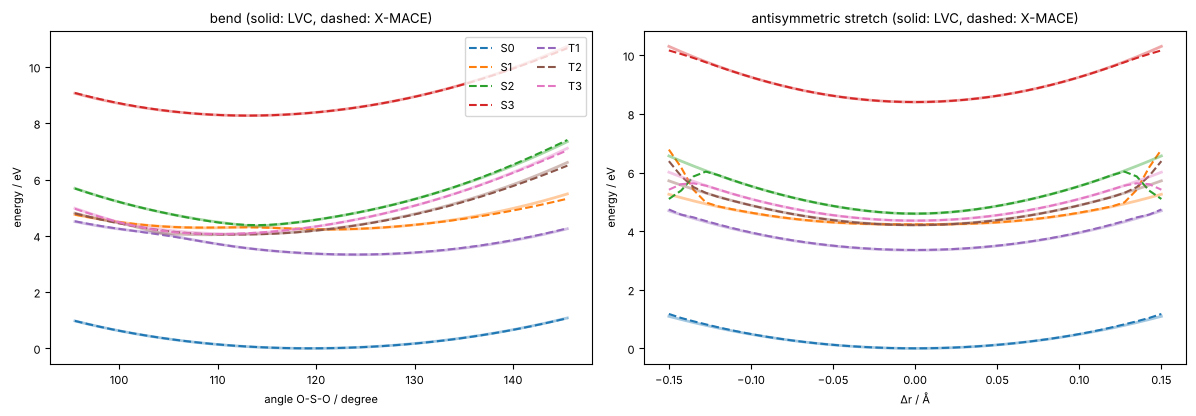

In [3]:
def so2_geometry(r1, r2, angle_deg):
    """S at the origin, both O in the yz plane (Å)."""
    half = np.radians(angle_deg) / 2
    return np.array([
        [0.0, 0.0, 0.0],
        [0.0, -r1 * np.sin(half), r1 * np.cos(half)],
        [0.0, r2 * np.sin(half), r2 * np.cos(half)],
    ])


r0 = np.linalg.norm(so2.positions[1] - so2.positions[0])
u, w = so2.positions[1] - so2.positions[0], so2.positions[2] - so2.positions[0]
a0 = np.degrees(np.arccos(u @ w / np.linalg.norm(u) / np.linalg.norm(w)))
print(f"reference geometry: r(S-O) = {r0:.3f} Å, angle = {a0:.1f}°")

scans = {
    "bend": (np.linspace(a0 - 25, a0 + 25, 41), lambda t: so2_geometry(r0, r0, t), "angle O-S-O / degree"),
    "antisymmetric stretch": (np.linspace(-0.15, 0.15, 41), lambda t: so2_geometry(r0 + t, r0 - t, a0), "Δr / Å"),
}
results = {}
for name, (grid, geometry, _) in scans.items():
    positions = np.array([geometry(t) for t in grid])
    reference = lvc.lvc_reference(WORK / "lvc_model", positions / lvc.BOHR_TO_ANGSTROM)
    from mace.data.sharc_labels import labels_from_sharc

    ref = [labels_from_sharc(STATES, h, g, n, d) for h, g, n, d in zip(reference["h"], reference["grad"], reference["nacdr"], reference["dm"])]
    pred = [calc.predict(ase.Atoms(v0["symbols"], positions=p)) for p in positions]
    results[name] = (grid, ref, pred)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
for ax, (name, (grid, ref, pred)) in zip(axes, results.items()):
    for s in range(7):
        ax.plot(grid, [r["energies"][s] for r in ref], color=f"C{s}", lw=2, alpha=0.4)
        ax.plot(grid, [p["energies"][s] for p in pred], color=f"C{s}", ls="--", label=NAMES[s])
    ax.set(xlabel=scans[name][2], ylabel="energy / eV", title=f"{name} (solid: LVC, dashed: X-MACE)")
axes[0].legend(fontsize=8, ncol=2)
plt.tight_layout()

And the couplings along the antisymmetric stretch: the NAC between S1 and S2 (index
of the pair in `calc.layout.nac_pairs`), the strongest SOC, and the transition
dipole S0–S1. Couplings are compared as norms, which do not depend on the phase.

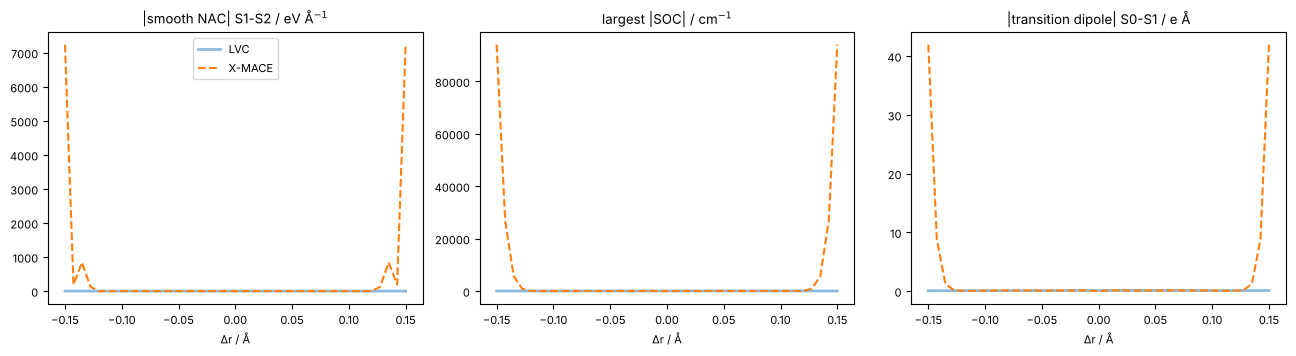

In [4]:
grid, ref, pred = results["antisymmetric stretch"]
pairs = calc.layout.nac_pairs
p12 = pairs.index((1, 2))
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
axes[0].plot(grid, [np.linalg.norm(r["nacs"][:, p12] * abs(r["energies"][2] - r["energies"][1])) for r in ref], lw=2, alpha=0.5, label="LVC")
axes[0].plot(grid, [np.linalg.norm(p["smooth_nacs"][:, p12]) for p in pred], ls="--", label="X-MACE")
axes[0].set(title="|smooth NAC| S1-S2 / eV Å$^{-1}$", xlabel="Δr / Å")
axes[1].plot(grid, [np.abs(r["socs"]).max() for r in ref], lw=2, alpha=0.5)
axes[1].plot(grid, [np.abs(p["soc_matrix"]).max() for p in pred], ls="--")
axes[1].set(title="largest |SOC| / cm$^{-1}$", xlabel="Δr / Å")
t01 = 7 + pairs.index((0, 1))
axes[2].plot(grid, [np.linalg.norm(r["dipoles"][t01]) for r in ref], lw=2, alpha=0.5)
axes[2].plot(grid, [np.linalg.norm(p["dipoles"][t01]) for p in pred], ls="--")
axes[2].set(title="|transition dipole| S0-S1 / e Å", xlabel="Δr / Å")
axes[0].legend()
plt.tight_layout()

Two things stand out.

**Away from the training data** (|Δr| > 0.1 Å, angles beyond ~135°) the predictions
drift from the reference: there is little data there (see the sampling plot in
Tutorial 2). This is the reason to sample the regions the dynamics visits and to use
committees to detect extrapolation (Tutorial 9).

**At Δr = 0 all three couplings of X-MACE drop to zero, while the reference does
not.** This is not a training problem but symmetry. At Δr = 0 the molecule has C2v
symmetry: a 180° rotation about the C2 axis maps it onto itself (swapping the two O
atoms). A model that is exactly rotation-equivariant and treats identical atoms
identically must then give a vector that does not change under this rotation, i.e.
one along the C2 axis. But the electronic states themselves belong to symmetry species
of the point group, and a coupling between states of different species (here S1–S2,
S0–S1 and the strongest SOC) changes sign under the C2 rotation: it must be
*perpendicular* to the axis. The only vector that satisfies both is zero. (The
phase of the states absorbs the sign for the reference, not for a function of the
geometry.) The `--coupling_parity=both` trick of Tutorial 1 removes this problem for
mirror planes, but not for rotation axes.

Consequences in practice:

* couplings between states of different point-group symmetry are underestimated in a
  small region around symmetric geometries (here |Δr| ≲ 0.01 Å) — the error is a
  narrow dip, and it shows up as the vertical stripes in the NAC, SOC and transition
  dipole parity plots of Tutorial 3;
* molecules without symmetry are not affected; for symmetric molecules, check the
  couplings along symmetry-breaking coordinates as above;
* phase-free quantities (such as the outer product **v v**ᵀ of a coupling vector) do
  not have this restriction — a possible future extension of X-MACE.

## 3. Symmetry checks on the trained model

The symmetries from Tutorial 1 hold for any parameters, so also after training:

In [5]:
from scipy.spatial.transform import Rotation

from mace.modules.spin_states import spin_rotation

distorted = ase.Atoms(v0["symbols"], positions=so2_geometry(r0 + 0.04, r0 - 0.02, a0 + 5))
R = Rotation.random(random_state=7).as_matrix()
rotated = distorted.copy()
rotated.positions = distorted.positions @ R.T
out, out_rot = calc.predict(distorted), calc.predict(rotated)
U = spin_rotation(STATES, R)
print("energies invariant:   ", np.allclose(out_rot["energies"], out["energies"]))
print("forces rotate:        ", np.allclose(out_rot["forces_states"], out["forces_states"] @ R.T))
print("SOC matrix rotates:   ", np.allclose(out_rot["soc_matrix"], U @ out["soc_matrix"] @ U.conj().T))
print("SOC matrix Hermitian: ", np.allclose(out["soc_matrix"], out["soc_matrix"].conj().T))

energies invariant:    True
forces rotate:         True
SOC matrix rotates:    True
SOC matrix Hermitian:  True


## 4. What SHARC receives: `SharcCalculator`

The SHARC interface (Tutorial 5) is a thin wrapper around `SharcCalculator`, which
you can also use directly. It takes coordinates in **bohr** and returns `QM.out`
quantities in **atomic units**, M_S-resolved:

* `h` — energies on the diagonal (every M_S component), plus the SOC matrix;
* `grad` — gradients for every M_S state;
* `nacdr` — NACs between states of equal multiplicity and equal M_S;
* `dm` — dipole matrices.

Units: the model was trained with energies in eV, lengths in Å and SOCs in cm⁻¹, so
`soc_to_au` must convert cm⁻¹ to Hartree (in the SHARC template this is
`soc_unit cm-1`).

h      (13, 13) complex128
grad   (13, 3, 3) float64
nacdr  (13, 13, 3, 3) float64
dm     (3, 13, 13) float64


energies (eV), LVC:    [0.115 4.22  4.895 8.593 3.331 4.398 4.641]
energies (eV), X-MACE: [0.115 4.222 4.894 8.592 3.34  4.39  4.642]


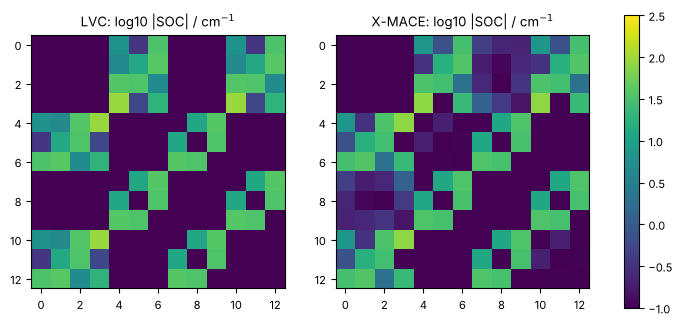

In [6]:
from mace.calculators.sharc_calculator import SharcCalculator

HARTREE_TO_INV_CM = 219474.6313632
sharc = SharcCalculator(
    atom_types=v0["symbols"],
    model_paths=str(WORK / "so2.model"),
    states=STATES,
    properties=["energy", "forces", "nacs", "socs", "dipoles"],
    soc_to_au=1.0 / HARTREE_TO_INV_CM,
)
coords_bohr = distorted.positions / lvc.BOHR_TO_ANGSTROM
qm = sharc.calculate(coords_bohr)
for key, value in qm.items():
    print(f"{key:6s} {value.shape} {value.dtype}")

reference = lvc.lvc_reference(WORK / "lvc_model", coords_bohr[None])
fig, axes = plt.subplots(1, 2, figsize=(9, 3.8))
for ax, (title, h) in zip(axes, (("LVC", reference["h"][0]), ("X-MACE", qm["h"]))):
    image = ax.imshow(np.log10(np.abs(h - np.diag(np.diag(h))) * HARTREE_TO_INV_CM + 1e-2), vmin=-1, vmax=2.5)
    ax.set(title=f"{title}: log10 |SOC| / cm$^{{-1}}$")
fig.colorbar(image, ax=axes)
print("energies (eV), LVC:   ", (np.diag(reference["h"][0]).real * 27.211386)[:7].round(3))
print("energies (eV), X-MACE:", (np.diag(qm["h"]).real * 27.211386)[:7].round(3))

Both SOC matrices have the same zeros (the selection rules); the magnitudes agree
where the model is accurate.

SHARC may ask for **fewer states** than the model knows; the lowest of each
multiplicity are used:

In [7]:
smaller = SharcCalculator(v0["symbols"], str(WORK / "so2.model"), states=[2, 0, 1],
                          properties=["energy", "forces", "nacs", "socs"], soc_to_au=1.0 / HARTREE_TO_INV_CM)
print("h for 2 singlets + 1 triplet:", smaller.calculate(coords_bohr)["h"].shape)

h for 2 singlets + 1 triplet: (5, 5)


## 5. Adiabatic dynamics on one state with ASE

Any ASE dynamics works with the calculator. Here: velocity-Verlet on S1 for 100 fs,
starting from a Wigner sample. This is **adiabatic** dynamics — the molecule stays
on S1; hopping between states needs SHARC (Tutorial 6). The total energy must be
conserved; a drift would indicate a non-smooth model or a too-large time step.

total-energy drift over 100 fs: 0.46 meV


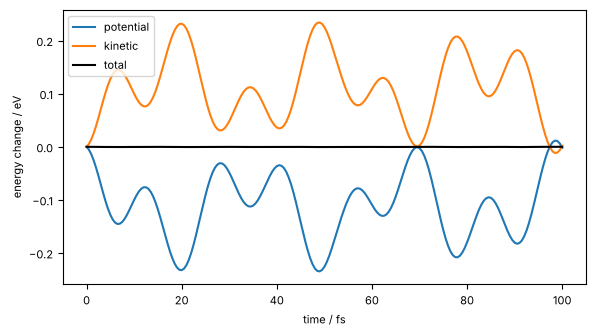

In [8]:
from ase import units
from ase.md.verlet import VelocityVerlet

sample = lvc.wigner_sample(v0, 1, seed=3)
atoms = ase.Atoms(v0["symbols"], positions=sample["coords"][0] * lvc.BOHR_TO_ANGSTROM)
atoms.calc = ExcitedMACECalculator(str(WORK / "so2.model"), device="cpu", state=1)
velocities_au = sample["velocities"][0]  # bohr per atomic time unit
atoms.set_velocities(velocities_au * lvc.BOHR_TO_ANGSTROM / (units._aut * 1e15) / units.fs)  # -> Å / ASE time

dyn = VelocityVerlet(atoms, timestep=0.5 * units.fs)
time_fs, e_pot, e_kin = [], [], []


def record():
    time_fs.append(dyn.get_time() / units.fs)
    e_pot.append(atoms.get_potential_energy())
    e_kin.append(atoms.get_kinetic_energy())


dyn.attach(record, interval=1)
dyn.run(200)
e_pot, e_kin = np.array(e_pot), np.array(e_kin)
plt.figure(figsize=(6, 3.4))
plt.plot(time_fs, e_pot - e_pot[0], label="potential")
plt.plot(time_fs, e_kin - e_kin[0], label="kinetic")
plt.plot(time_fs, e_pot + e_kin - (e_pot[0] + e_kin[0]), label="total", color="k")
plt.xlabel("time / fs"); plt.ylabel("energy change / eV"); plt.legend(); plt.tight_layout()
print(f"total-energy drift over {time_fs[-1]:.0f} fs: {np.ptp(e_pot + e_kin) * 1000:.2f} meV")

## 6. Evaluating a whole file

`mace_eval_configs` writes all predictions of an excited-state model into a new
extended XYZ file (keys `MACE_energies`, `MACE_forces`, `MACE_smooth_nacs`,
`MACE_nacs`, `MACE_soc_vectors`, `MACE_socs`, `MACE_dipoles`):

In [9]:
subprocess.run(
    ["mace_eval_configs", f"--configs={WORK / 'so2_test.xyz'}", f"--model={WORK / 'so2.model'}",
     f"--output={WORK / 'so2_test_predicted.xyz'}", "--device=cpu"],
    check=True, capture_output=True,
)
predicted = ase.io.read(WORK / "so2_test_predicted.xyz", 0)
print({k: np.shape(v) for k, v in predicted.info.items() if k.startswith("MACE_")})

{'MACE_energy': (), 'MACE_energies': (7,), 'MACE_forces': (3, 7, 3), 'MACE_smooth_nacs': (3, 9, 3), 'MACE_nacs': (3, 9, 3), 'MACE_soc_vectors': (15, 3), 'MACE_socs': (156,), 'MACE_dipoles': (16, 3)}


**Committees.** Passing several models (a list or a glob pattern such as
`"so2_seed*.model"`) gives the committee mean, and `energies_var` /
`forces_states_var` — a measure of how uncertain the prediction is. Tutorial 9 trains
a small committee.

**Next:** [Tutorial 6](06_surface_hopping_with_sharc.ipynb) runs surface hopping with
SHARC.